# ML Workflow, Data Preparation & Validation

**Session 18 study guide** · Python · pandas · scikit-learn · a synthetic housing file

**The business case.** A property agency wants a tool that gives agents a **first price estimate** for a house before it is listed. It has 300 past sales in a messy export: blanks, typos, duplicate rows and one column that should never be used.

Today's goal is **not** a great model. It is a workflow whose score we can **trust**. A model that looks brilliant because it secretly saw the answers is worse than useless: the agency would make decisions on a number that collapses on the first real listing.

| Step | Question | Tool |
| --- | --- | --- |
| 1 Frame | What exactly are we predicting, and what is known at that moment? | X, y, the feature contract |
| 2 Protect | How do we keep some evidence honest? | train / validation / test split, leakage |
| 3 Clean | What is wrong with the records, and how do we fix each kind? | fixed rules, imputation, outlier flags |
| 4 Represent | How do categories and big numbers become model inputs? | one-hot encoding, scaling |
| 5 Assemble | How do we apply the same steps every time? | scikit-learn Pipeline |
| 6 Reference | What score must a real model beat? | a baseline and MAE |
| 7 Rotate | Is one split enough? | cross-validation |

**One rule runs through everything:** learn every preparation setting from training rows only, then reuse it unchanged on validation rows and new houses.

The data file `S18_Housing_Study.csv` is **synthetic** (seed 18): 300 invented sales with defects added on purpose. Prices are in rand and area in m².

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

BLUE, LIGHT_BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#cfe0f6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "font.size": 10})

## Part 1 · Frame the prediction

**When is machine learning the right tool?**

| Job | Example | Tool |
| --- | --- | --- |
| Describe the past | "What was the median sale price last year?" | a summary: the answer is already in the table |
| Apply a known rule | "Transfer duty is a fixed % of the price" | a formula: no examples needed |
| Estimate an unknown | "What will **this** house sell for?" | **machine learning**: learn a pattern from past sales |

**Vocabulary.** Each row is an **observation** (one sale). The input columns are **features**, stored in **X**. The column we want to predict is the **target**, stored in **y**. **Fitting** (training) means learning a rule from rows where y is known; **predicting** means applying it to a new house where y is unknown.

Today's task is **supervised regression**: we supply inputs **and** known prices, and the output is a number. (Classification predicts a category; unsupervised learning finds groups with no target at all.)

**The prediction-moment test.** For every column ask: *would we know this for a new house **before** it sells?*

In [2]:
raw = pd.read_csv("S18_Housing_Study.csv", dtype=str, keep_default_na=False)   # load as text: see every token
print(raw.shape)
print(raw.head(3).to_string(index=False))

NUMERIC = ["area", "bedrooms", "bathrooms", "parking"]
CATEGORICAL = ["mainroad", "furnishingstatus"]
TARGET = "price"
FORBIDDEN = ["record_id", "price_per_m2_at_sale"]    # never inputs

(308, 9)
record_id area bedrooms bathrooms parking mainroad furnishingstatus   price price_per_m2_at_sale
    H0001  385        6         3       1      yes      unfurnished 6730000              17481.0
    H0002  426        6         2       0      yes      unfurnished 6470000              15188.0
    H0003  384        6         3       1      yes      unfurnished 6385000              16628.0


| Column | Known before the sale? | Role |
| --- | --- | --- |
| area, bedrooms, bathrooms, parking, mainroad, furnishingstatus | yes | **features (X)** |
| price | no: it is what we predict | **target (y)** |
| price_per_m2_at_sale | no: it is **built from the price** | **forbidden: leakage** |
| record_id | yes, but it describes the file, not the house | audit only |

`price_per_m2_at_sale` would make any model look excellent, because price ÷ area × area *is* the price. It would be useless on a new listing, where that column does not exist yet. Excluding it is decided by **availability**, not by how good the score looks.

> **Business meaning.** Framing is a contract with the agency: "we estimate the eventual sale price from six attributes an agent can record at the first visit." It also says what the tool is **not**: not a valuation for a bond application, and not proof that adding parking *causes* a higher price.

## Part 2 · Protect the evidence

**Everyday example.** A teacher who hands out the exam questions in advance learns nothing from the marks. To know whether a model **generalises** (works on new houses), we must score it on rows it never learned from.

**Step 1: remove exact duplicates first**, otherwise one sale could end up on both sides of the split and be "remembered" rather than predicted.

In [3]:
repeated = raw[raw["record_id"].duplicated(keep=False)].sort_values("record_id")
print("rows sharing a record_id:", len(repeated),
      "| all identical copies:", repeated.duplicated(keep=False).all())

data = raw.drop_duplicates().reset_index(drop=True)
X = data[NUMERIC + CATEGORICAL]
y = data[TARGET].astype(float)
ids = data["record_id"]
print("after removing copies:", data.shape, "| X:", X.shape, "| y:", y.shape)

rows sharing a record_id: 16 | all identical copies: True
after removing copies: (300, 9) | X: (300, 6) | y: (300,)


**Step 2: split into three partitions, each with one job.**

| Partition | Size | Allowed to... |
| --- | --- | --- |
| **Training** | 60% | **learn**: every median, scale, category list and model setting |
| **Validation** | 20% | **compare** candidate workflows during development |
| **Test** | 20% | give **one final check** after all choices are frozen (not opened today) |

We reserve the test set first, then split the rest. X, y and the IDs go into the **same** call so their rows stay aligned.

train 180 | validation 60 | test 60
ID overlap train/val: 0 | train/test: 0


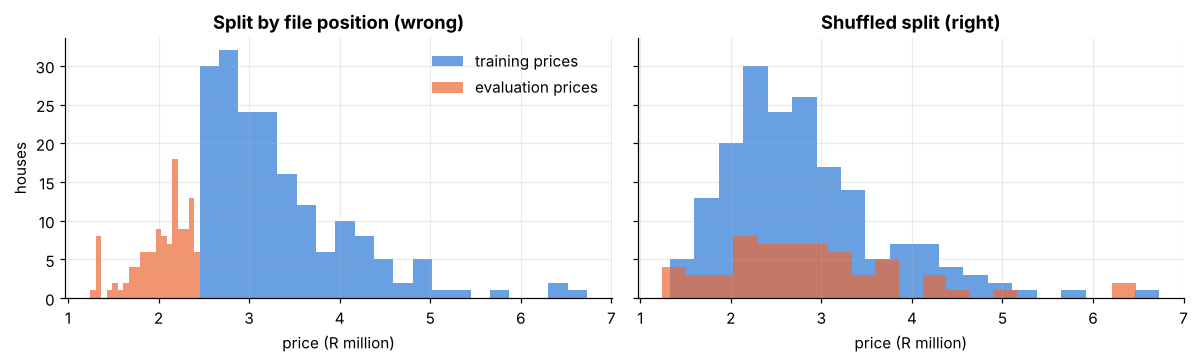

In [4]:
X_dev, X_test, y_dev, y_test, id_dev, id_test = train_test_split(
    X, y, ids, test_size=0.20, shuffle=True, random_state=42)
X_train, X_val, y_train, y_val, id_train, id_val = train_test_split(
    X_dev, y_dev, id_dev, test_size=0.25, shuffle=True, random_state=42)

print(f"train {len(X_train)} | validation {len(X_val)} | test {len(X_test)}")
print("ID overlap train/val:", len(set(id_train) & set(id_val)),
      "| train/test:", len(set(id_train) & set(id_test)))

# Why shuffle? The file is sorted by price, highest first.
cut = int(len(y) * 0.6)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, (title, tr, ev) in zip(axes, [("Split by file position (wrong)", y[:cut], y[cut:]),
                                       ("Shuffled split (right)", y_train, y_val)]):
    ax.hist(tr / 1e6, bins=20, alpha=0.7, color=BLUE, label="training prices")
    ax.hist(ev / 1e6, bins=20, alpha=0.7, color=ORANGE, label="evaluation prices")
    ax.set(title=title, xlabel="price (R million)")
axes[0].set_ylabel("houses")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

**Reading the chart.** Taking the first 60% of a price-sorted file trains on expensive houses and evaluates on cheap ones: two different worlds. Shuffling gives both partitions the same mix. (`random_state=42` makes the split **repeatable**, not automatically representative. Time-ordered data, such as forecasting next month's sales, needs a time-based split instead.)

**Leakage = information crossing the boundary** from the held-out side into what the model learns:

| Route | Example | Protection |
| --- | --- | --- |
| A feature contains the answer | price_per_m2_at_sale | the feature contract (Part 1) |
| Preparation learned from held-out rows | a median computed on **all** rows | fit only on training rows (Part 5) |
| The same record on both sides | a duplicate row | dedupe before splitting |
| Test results steer choices | tune, check test, tune again | open the test set once, at the end |

**Why "fit on training only" matters, in one line of arithmetic:**

In [5]:
train_values = np.array([10, 20, 30])
print("mean of training rows:              ", train_values.mean())
print("mean if one held-out row sneaks in: ", np.append(train_values, 1000).mean())

mean of training rows:               20.0
mean if one held-out row sneaks in:  265.0


The rule "fill blanks with the mean" is the same, but the **learned value** jumps from 20 to 265 because one held-out row was allowed in. Medians, scales and category lists are learned values too.

> **Business meaning.** The validation score is the agency's preview of real-world performance. Every leak makes that preview look better than reality, so the agency would launch a tool that disappoints in practice.

## Part 3 · Clean imperfect records

Diagnose **what kind** of problem each value has before choosing a repair. We inspect **training rows only**.

In [6]:
def unusual_tokens(column):
    """Values in a numeric column that are blank or not plain whole numbers."""
    values = X_train[column].str.strip()
    return values[~values.str.fullmatch(r"\d+")].value_counts().to_dict()

for col in NUMERIC:
    print(f"{col:<10}", unusual_tokens(col))
for col in CATEGORICAL:
    print(f"{col:<17}", X_train[col].value_counts().to_dict())

area       {'-10': 2, '': 2, '244 m2': 1}
bedrooms   {}
bathrooms  {'1 baths': 2, '': 2, '3 baths': 1}
parking    {}
mainroad          {'yes': 136, 'no': 38, ' YES ': 3, '': 3}
furnishingstatus  {'unfurnished': 70, 'semi-furnished': 63, 'furnished': 44, 'semi furnished': 2, '': 1}


| Value | What it is | Action |
| --- | --- | --- |
| `""` (blank) | missing | keep the row; fill later with a **training** median or mode |
| `"150 m2"`, `"2 baths"` | a valid number with a unit | parse to 150 and 2 |
| `" YES "`, `"semi furnished"` | a known spelling variant | normalise to `yes`, `semi-furnished` |
| `"-10"`, `"0"` area | impossible | treat as missing |
| parking `"0"` | a real count of zero | **keep** 0 |
| `"about 150"` (on a new row) | an unknown format | **raise an error**; never guess |

Two kinds of preparation step:

- **Fixed rules** depend only on the value's meaning ("strip ' m2'", "area ≤ 0 is impossible"). They are the same for every row and safe to apply anywhere.
- **Learned settings** depend on the distribution of the data (a median, a mode, a scale). They must be **fit on training rows only**.

**The fixed rules, as one reusable function.** It also builds a new feature, `area_per_bedroom`, using only inputs known before the sale:

In [7]:
def parse_number(series, unit_pattern=None):
    """Text -> number. Strips a known unit; blanks become NaN; unknown formats raise an error."""
    text = series.str.strip()
    if unit_pattern:
        text = text.str.replace(unit_pattern, "", regex=True).str.strip()
    numbers = pd.to_numeric(text.where(text != ""), errors="coerce")
    unknown = text[(text != "") & numbers.isna()]
    if len(unknown):
        raise ValueError(f"{series.name}: unknown format {unknown.unique().tolist()}")
    return numbers

def clean_features(X):
    """Fixed, row-by-row rules. Learns nothing from the data."""
    X = X.copy()
    X["area"] = parse_number(X["area"], r"\s*m2$")
    X.loc[X["area"] <= 0, "area"] = np.nan                         # impossible -> missing
    X["bathrooms"] = parse_number(X["bathrooms"], r"\s*baths?$")
    X["bedrooms"] = parse_number(X["bedrooms"])
    X["parking"] = parse_number(X["parking"])                       # 0 stays 0
    for col in CATEGORICAL:
        X[col] = (X[col].str.strip().str.lower()
                  .replace({"": np.nan, "semi furnished": "semi-furnished"}))
    X["area_per_bedroom"] = X["area"] / X["bedrooms"].where(X["bedrooms"] > 0)   # never divide by 0
    return X

clean_train = clean_features(X_train)
print("missing after fixed rules:", clean_train.isna().sum()[lambda s: s > 0].to_dict())
print("parking zeros kept:", (clean_train["parking"] == 0).sum())
try:
    clean_features(pd.DataFrame([{"area": "about 150", "bedrooms": "3", "bathrooms": "2",
                                  "parking": "1", "mainroad": "yes", "furnishingstatus": "furnished"}]))
except ValueError as err:
    print("new row rejected ->", err)

missing after fixed rules: {'area': 4, 'bathrooms': 2, 'mainroad': 3, 'furnishingstatus': 1, 'area_per_bedroom': 4}
parking zeros kept: 61
new row rejected -> area: unknown format ['about 150']


**Missing values.** For numbers we fill with the **training median**: one mansion barely moves a median but can drag a mean. For categories we fill with the **training mode** (most common value). Filling is a practical patch, not the truth. A **missing target** can never be filled: a row without a price cannot teach or test anything.

**Outliers: flag, don't delete.** The IQR rule flags values above Q3 + 1.5 × IQR, computed on training rows:

Q1 = 117.8 | Q3 = 185.2 | IQR = 67.5 | flag above 286.5 m²
flagged areas: [287, 304, 314, 315, 337, 385, 404]


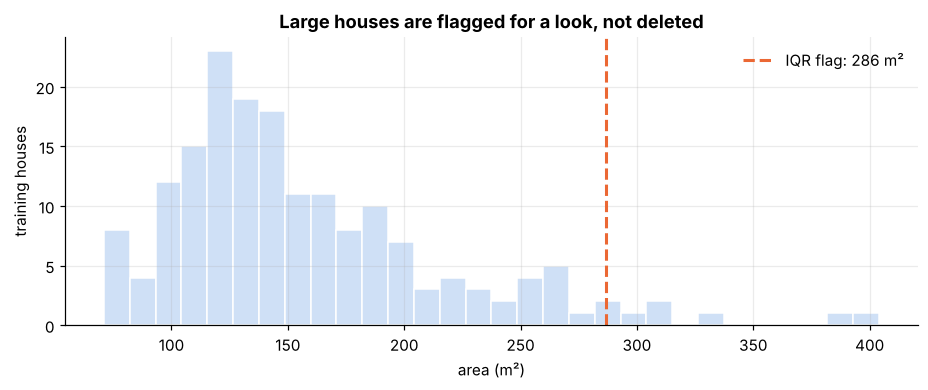

In [8]:
area = clean_train["area"].dropna()
q1, q3 = area.quantile([0.25, 0.75])
flag = q3 + 1.5 * (q3 - q1)
print(f"Q1 = {q1:.1f} | Q3 = {q3:.1f} | IQR = {q3 - q1:.1f} | flag above {flag:.1f} m²")
print("flagged areas:", sorted(area[area > flag].astype(int)))

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(area, bins=30, color=LIGHT_BLUE, edgecolor="white")
ax.axvline(flag, color=ORANGE, linestyle="--", linewidth=2, label=f"IQR flag: {flag:.0f} m²")
ax.set(xlabel="area (m²)", ylabel="training houses", title="Large houses are flagged for a look, not deleted")
ax.legend(frameon=False)
plt.show()

The seven flagged houses are big but plausible (about 290–400 m²). Deleting them would teach the model that big houses do not exist, and its first big listing would be badly under-priced. Delete a value only with **evidence** it is wrong, such as a unit mix-up or a typo confirmed in the source system.

> **Business meaning.** Every cleaning decision is a business assumption. "Blank area gets the typical area" is fine for a first estimate, but the agent should be told the estimate used a filled-in value.

## Part 4 · Represent mixed features

**Categories need indicator columns, not codes.** Coding unfurnished = 1, semi = 2, furnished = 3 invents a ruler: it claims "semi" sits exactly halfway and furnished is "three times" unfurnished. **One-hot encoding** gives each category its own 0/1 column instead.

**Big numbers need a common scale.** Area is in the hundreds, bathrooms are 1 to 4. Many models compare or penalise inputs, so the big one would dominate. **Standardising** turns each value into "how many training standard deviations from the training mean": z = (x − mean) ÷ SD.

Both are **learned settings**, so both are fit on training rows only. A small demo:

In [9]:
furnish_train = clean_train[["furnishingstatus"]].dropna()
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(furnish_train)
print("learned categories:", encoder.categories_[0].tolist())
demo = pd.DataFrame({"furnishingstatus": ["furnished", "unfurnished", "part-furnished"]})
print(pd.DataFrame(encoder.transform(demo), index=demo["furnishingstatus"],
                   columns=encoder.categories_[0]).astype(int))

scaler = StandardScaler().fit(clean_train[["area"]].dropna())
print(f"\nlearned area mean {scaler.mean_[0]:.1f} m², SD {scaler.scale_[0]:.1f} m²")
print("a 250 m² house ->", scaler.transform(pd.DataFrame({"area": [250]}))[0, 0].round(2),
      "SDs above the training mean")

learned categories: ['furnished', 'semi-furnished', 'unfurnished']
                  furnished  semi-furnished  unfurnished
furnishingstatus                                        
furnished                 1               0            0
unfurnished               0               0            1
part-furnished            0               0            0

learned area mean 157.4 m², SD 59.6 m²
a 250 m² house -> 1.55 SDs above the training mean


`part-furnished` never appeared in training, so it becomes **[0, 0, 0]**: "none of the known categories". It does **not** mean unfurnished, and the model has learned nothing about it. In production, new categories should be logged and reviewed.

> **Watch out.** Scaling does not make data normal and does not fix outliers. A new value outside the training range is simply transformed to a large z, which is correct behaviour, not an error.

## Part 5 · Assemble one pipeline

Doing these steps by hand invites mistakes: forgetting a step on new data, or fitting a scaler on the wrong rows. A scikit-learn **Pipeline** bundles them so that:

| Call | What happens | Which rows |
| --- | --- | --- |
| `Pipeline([...])` | describes the steps; nothing learned yet | none |
| `.fit(X_train, y_train)` | learns every median, mode, scale, category list and the model | **training only** |
| `.predict(X_val)` | applies the stored settings, then predicts; learns nothing | validation or new houses |

A **ColumnTransformer** sends numeric and categorical columns down different routes side by side:

> raw 6 columns → **clean** (fixed rules + area_per_bedroom) → **numeric route**: median impute → scale · **categorical route**: mode impute → one-hot → **model**

In [10]:
NUMERIC_WITH_RATIO = NUMERIC + ["area_per_bedroom"]

numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
categorical_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                             ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
columns = ColumnTransformer([("num", numeric_pipe, NUMERIC_WITH_RATIO),
                             ("cat", categorical_pipe, CATEGORICAL)], remainder="drop")

def make_workflow(model):
    """Same preparation every time; only the final model changes."""
    return Pipeline([("clean", FunctionTransformer(clean_features)), ("columns", columns), ("model", model)])

baseline = make_workflow(DummyRegressor(strategy="median")).fit(X_train, y_train)

prep = baseline.named_steps["columns"]
names = prep.get_feature_names_out()
print(len(names), "prepared columns:", list(names))
medians = prep.named_transformers_["num"]["impute"].statistics_
print("learned numeric medians:", {col: float(v) for col, v in zip(NUMERIC_WITH_RATIO, medians)})
print("learned modes:", prep.named_transformers_["cat"]["impute"].statistics_.tolist())

val_matrix = prep.transform(clean_features(X_val))
print("validation matrix:", val_matrix.shape, "| any missing:", np.isnan(val_matrix).any())

10 prepared columns: ['num__area', 'num__bedrooms', 'num__bathrooms', 'num__parking', 'num__area_per_bedroom', 'cat__mainroad_no', 'cat__mainroad_yes', 'cat__furnishingstatus_furnished', 'cat__furnishingstatus_semi-furnished', 'cat__furnishingstatus_unfurnished']
learned numeric medians: {'area': 142.5, 'bedrooms': 3.0, 'bathrooms': 1.0, 'parking': 1.0, 'area_per_bedroom': 55.5}
learned modes: ['yes', 'unfurnished']


validation matrix: (60, 10) | any missing: False


**Checks that the preparation behaves:** 10 columns (5 numeric + 2 mainroad + 3 furnishing), the same names for training and validation, no missing values left, and the learned medians come from the 180 training rows only. Transforming validation rows reused those settings and learned nothing new.

> **Why it matters in practice.** The fitted pipeline is **one object** you can save and deploy. A new raw listing goes in exactly as an agent types it, and the same cleaning, filling, scaling and encoding happen automatically. That consistency between training and production is where many real ML projects fail.

## Part 6 · Set an honest reference

Before building a clever model, ask: **what score would a lazy guess get?** The simplest baseline predicts the **training median price for every house**. A real model must beat it, or it adds nothing.

**MAE (mean absolute error)** = the average size of a miss, in rand. Example: actual prices 100, 150, 210; constant guess 140; misses 40, 10, 70; MAE = (40 + 10 + 70) ÷ 3 = 40. Lower is better. It is **not** a percentage accuracy.

baseline predicts R2,652,500 for every house (training median: R2,652,500)
validation MAE: R764,500   check by hand: R764,500


mean baseline: predicts R2,809,611 | validation MAE: R759,224

new raw listing (blank area, unseen furnishing) -> R2,652,500


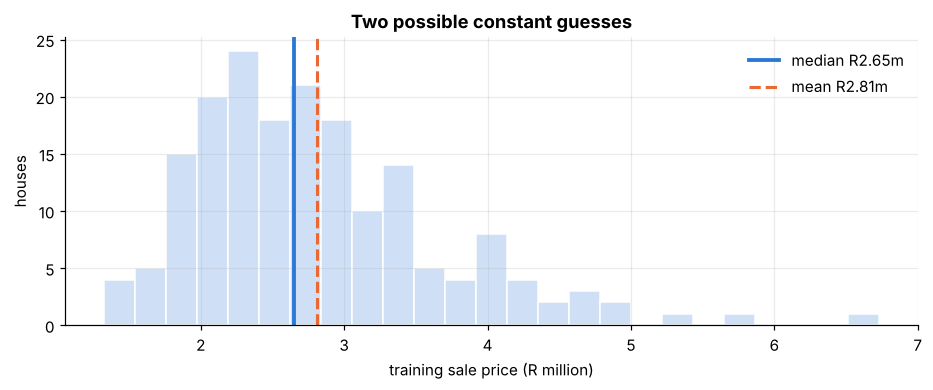

In [11]:
pred_val = baseline.predict(X_val)
mae_median = mean_absolute_error(y_val, pred_val)
print(f"baseline predicts R{pred_val[0]:,.0f} for every house (training median: R{np.median(y_train):,.0f})")
print(f"validation MAE: R{mae_median:,.0f}   check by hand: R{np.mean(np.abs(y_val - pred_val)):,.0f}")

mean_baseline = make_workflow(DummyRegressor(strategy="mean")).fit(X_train, y_train)
mae_mean = mean_absolute_error(y_val, mean_baseline.predict(X_val))
print(f"mean baseline: predicts R{y_train.mean():,.0f} | validation MAE: R{mae_mean:,.0f}")

new_listing = pd.DataFrame([{"area": "", "bedrooms": "3", "bathrooms": "2", "parking": "1",
                             "mainroad": "yes", "furnishingstatus": "part-furnished"}])
print(f"\nnew raw listing (blank area, unseen furnishing) -> R{baseline.predict(new_listing)[0]:,.0f}")

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(y_train / 1e6, bins=25, color=LIGHT_BLUE, edgecolor="white")
ax.axvline(np.median(y_train) / 1e6, color=BLUE, linewidth=2.5, label=f"median R{np.median(y_train)/1e6:.2f}m")
ax.axvline(y_train.mean() / 1e6, color=ORANGE, linestyle="--", linewidth=2, label=f"mean R{y_train.mean()/1e6:.2f}m")
ax.set(xlabel="training sale price (R million)", ylabel="houses", title="Two possible constant guesses")
ax.legend(frameon=False)
plt.show()

**Reading the output.** Guessing about R2.65 million for every house misses by about **R765,000** on average. The mean baseline does very slightly better on these 60 validation houses (R759,000), a gap of about R5,000 that could easily flip on another split. The new listing, with a blank area and an unknown furnishing label, went through without errors, but it still gets the same constant: a baseline ignores every feature.

> **Business meaning.** "About R760,000 off on average" is the bar. If a model can't beat it, agents are better off quoting the typical price. A constant's score also proves nothing about the features: adding the forbidden price-per-m² column would not change it, which is why leakage is judged by availability, never by the score.

## Part 7 · Rotate the evidence: cross-validation

One validation split of 60 houses can be lucky or unlucky (the median and mean baselines just swapped places by a few thousand rand). **K-fold cross-validation** splits the development data (training + validation, 240 houses) into 5 folds, holds out each fold once, and **refits the whole pipeline** on the other 4 each time. The test set stays outside every fold.

As a preview of the next session, we also try a real model, **linear regression**, in the same pipeline.

median baseline    fold MAEs (R thousand): [760. 761. 656. 459. 776.] | mean R682,104
mean baseline      fold MAEs (R thousand): [745. 772. 675. 489. 770.] | mean R690,158


linear regression  fold MAEs (R thousand): [386. 357. 336. 302. 368.] | mean R349,858


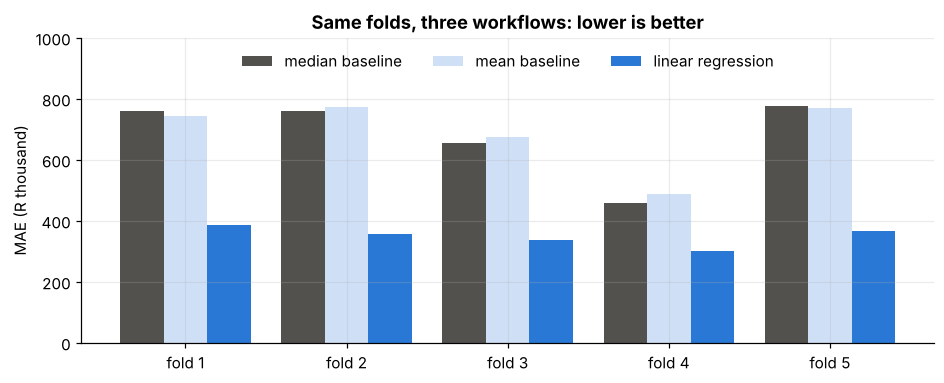

In [12]:
folds = KFold(n_splits=5, shuffle=True, random_state=42)
candidates = {"median baseline": DummyRegressor(strategy="median"),
              "mean baseline": DummyRegressor(strategy="mean"),
              "linear regression": LinearRegression()}

scores = {}
for name, model in candidates.items():
    mae = -cross_val_score(make_workflow(model), X_dev, y_dev, cv=folds, scoring="neg_mean_absolute_error")
    scores[name] = mae
    print(f"{name:<18} fold MAEs (R thousand): {(mae / 1000).round(0)} | mean R{mae.mean():,.0f}")

fig, ax = plt.subplots(figsize=(10, 3.6))
width = 0.27
for i, ((name, mae), colour) in enumerate(zip(scores.items(), [MUTED, LIGHT_BLUE, BLUE])):
    ax.bar(np.arange(5) + (i - 1) * width, mae / 1000, width, color=colour, label=name)
ax.set(xticks=range(5), xticklabels=[f"fold {k}" for k in range(1, 6)], ylabel="MAE (R thousand)",
       ylim=(0, 1000), title="Same folds, three workflows: lower is better")
ax.legend(frameon=False, ncol=3, loc="upper center")
plt.show()

**Reading the chart.** The two baselines are almost identical in every fold. On average the median baseline now edges ahead (R682,000 against R690,000), the opposite of the single validation split: neither constant is really "better". Linear regression roughly **halves** the error (about R350,000 against R680,000) in **every** fold, so its advantage is not luck of one split. The fold-to-fold spread (for example R459,000 to R776,000 for the median baseline) shows how much a single split can vary.

> **Business meaning.** Now the agency has an honest claim: "on houses the model never saw, estimates were off by about R350,000 on average, against R680,000 for quoting the typical price". The test set is still unopened: it is used once, after the final model is chosen, to confirm this number.

## Summary

| What today's workflow supports | What it does **not** support |
| --- | --- |
| 8 duplicate copies were removed before splitting | that the model is ready to value real houses |
| training, validation and test rows never overlap | that area_per_bedroom improves predictions (not tested) |
| every learned setting came from training rows only | that any feature **causes** a higher price |
| a raw new listing with a blank and an unseen category is handled | that the cross-validation MAE is the final test result |
| linear regression beat the baseline in all 5 folds | that synthetic results transfer to a real market |

**The workflow checklist**

1. **Frame:** name the target, the prediction moment and which columns are known at that moment.
2. **Dedupe, then split** (train / validation / test), keeping X, y and IDs aligned.
3. **Fixed rules** for formats and impossible values; **learned settings** fit on training only.
4. **One-hot** categories, **scale** numbers, inside a **Pipeline**.
5. Score a **baseline** first; compare candidates on the **same** rows or folds.
6. Open the **test set once**, at the end.

### Check your understanding

1. Why is `price_per_m2_at_sale` forbidden even though it would give a much lower error?
2. Why must duplicates be removed **before** the split?
3. A new listing says furnishing is "part-furnished". What does the pipeline do, and what does it **not** do?
4. Why fill a blank area with the **training** median and not the median of all rows?
5. A model's validation MAE is R40,000 worse than the baseline. What do you conclude?

In [13]:
# Try it: remove "area_per_bedroom" from NUMERIC_WITH_RATIO (and from clean_features),
# rerun Parts 5 and 7, and compare the linear-regression fold MAEs. Did the feature help?

### Answers

1. It is computed from the sale price, so it does not exist for a new listing. Leakage is judged by availability, not by the score.
2. Otherwise one sale can sit in both training and validation, and the model is scored on something it has already seen.
3. It encodes it as [0, 0, 0] and still predicts. It does **not** understand the new category; it should be logged and reviewed.
4. Validation and test rows must not influence anything the workflow learns; otherwise the score is optimistic.
5. The model adds nothing over quoting the typical price. Don't use it; investigate the features or try another model.

**Next session:** Regression Models & Evaluation: models that learn from the features, judged against this baseline.

*Data: S18_Housing_Study.csv is synthetic (300 invented sales plus 8 duplicate copies, with defects added on purpose; seed 18).*